# One participant, step by step

This notebook analyses one participant of **ERP CORE** (Kappenman et al., 2021, *NeuroImage*
225:117465), a public dataset recorded for exactly this purpose: reproducing standard ERP
effects. In the P3 task, letters A-E appear one at a time; in each block one letter is the
target. The **P3** is the positive wave over the back of the head, 300-600 ms after a rare target,
compared with the frequent non-targets.

We go through every analysis step with BrainO's tools, approve the two decisions (which ICA
components to remove, which channels are bad), measure the P3, and compare it with the authors'
published score for this participant. The data (about 55 MB) are downloaded and checked against
pinned hashes the first time.

In [1]:
import shutil
import warnings
from pathlib import Path

warnings.simplefilter("ignore")  # keep the outputs readable

from braino.datasets import erpcore


def working_copy(task, subjects, folder):
    """Download (or reuse) ERP CORE data and copy it to a folder of its own, so this
    notebook's outputs do not mix with other analyses of the cached data."""
    source = erpcore.fetch(task, subjects)
    target = Path(folder)
    if target.exists():
        shutil.rmtree(target)
    keep = {f"sub-{s}" for s in subjects}
    shutil.copytree(
        source,
        target,
        ignore=lambda folder, names: [
            n for n in names
            if Path(folder) == source and (n == "derivatives" or (n.startswith("sub-") and n not in keep))
        ],
    )
    return target

In [2]:
root = working_copy("P3", ["001"], "work/erpcore-p3-one")

from braino.tools import RunContext, decide, registry

ctx = RunContext(dataset_root=root)  # where data are read and outputs written; one run ID


def run(tool, **args):
    """Run a tool on participant 001's P3 recording."""
    return registry.get(tool).run({"subject": "001", "task": "P3", **args}, ctx)


registry.get("dataset.inspect").run({}, ctx).recordings[0]

RecordingSummary(subject='001', session=None, task='P3', run=None, datatype='eeg', path='sub-001/eeg/sub-001_task-P3_eeg.set', sampling_rate_hz=1024.0, duration_s=467.0, line_freq_hz=60.0, channels={'eeg': 30, 'eog': 3}, bad_channels=[], events={'response': 202, 'stimulus': 200})

## Data quality

A first look, changing nothing: flat or noisy channels, line noise, and how much of the time has
large artifacts.

In [3]:
qc = run("eeg.qc_report")
print(f"{qc.n_channels_checked} channels; flat: {qc.flat}; noisy: {qc.noisy}")
print(f"line noise median ratio {qc.line_noise_median_ratio}; "
      f"{qc.artifact_fraction:.0%} of 1-s windows with large artifacts")

30 channels; flat: []; noisy: []
line noise median ratio 1.59; 34% of 1-s windows with large artifacts


## Preprocessing

The settings ERP CORE used: high-pass 0.1 Hz, low-pass 30 Hz, resampling to 256 Hz, and the
average of the mastoid-like P9 and P10 electrodes as reference. The original recording is not
changed; a preprocessed copy goes to `derivatives/braino/`.

In [4]:
pre = run("eeg.preprocess", l_freq=0.1, h_freq=30.0, resample_hz=256, reference=["P9", "P10"])
pre.steps, pre.positions, pre.notes

(['band-pass 0.1-30 Hz (fir, zero-phase)',
  'resample 1024 -> 256 Hz',
  'reference: mean of P9, P10'],
 'template',
 ['Electrode positions are approximate, taken from the standard colin27_1005 layout for 30 of 30 EEG channels.'])

## Decision 1: ICA components

`eeg.ica_clean` fits ICA and labels each component with ICLabel. It does not remove anything: it
**proposes** removing the eye-blink and heart components. A person looks and decides.

In [5]:
proposal = run("eeg.ica_clean")
print("proposed for removal:", proposal.proposal["exclude"])
for c in proposal.proposal["components"][:10]:
    print(f"  {c['index']:>2}  {c['label']:<16} p = {c['probability']:.2f}   "
          f"{c['explained_variance']:.1%} of variance")

proposed for removal: [0, 8]
   0  eye blink        p = 0.99   35.0% of variance
   1  other            p = 0.91   13.2% of variance
   2  brain            p = 1.00   9.3% of variance
   3  muscle artifact  p = 0.97   5.0% of variance
   4  eye blink        p = 0.44   5.7% of variance
   5  brain            p = 1.00   4.3% of variance
   6  other            p = 0.82   3.9% of variance
   7  brain            p = 1.00   2.9% of variance
   8  eye blink        p = 0.97   2.9% of variance
   9  brain            p = 0.45   2.3% of variance


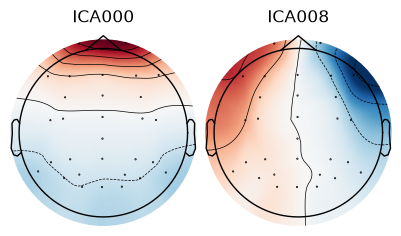

In [6]:
import mne

ica = mne.preprocessing.read_ica(root / proposal.proposal["ica_file"], verbose="error")
raw = mne.io.read_raw_fif(root / proposal.proposal["recording"], verbose="error")
ica.plot_components(picks=proposal.proposal["exclude"], inst=raw, show=False);

The proposed components have the frontal topography of blinks. Approve; the decision (and who
made it) is recorded with the proposal.

In [7]:
record = decide(proposal.proposal_id, ctx, approve=True, decided_by="user:example")
record.decision.apply_result

{'output': 'derivatives/braino/sub-001/eeg/sub-001_task-P3_desc-clean_eeg.fif',
 'removed': [0, 8],
 'removed_labels': {'0': 'eye blink', '8': 'eye blink'},
 'reference': ['P9', 'P10']}

## Decision 2: bad channels

Run after ICA, so that eye activity does not make the channels near the eyes look bad (BrainO's
documentation explains why this order works better). The proposal says why each channel was
found bad; you could also edit the list (`edits={"channels": [...]}`) or reject it.

In [8]:
proposal = run("eeg.detect_bad_channels")
print(proposal.proposal["reasons"])
print(proposal.proposal["notes"])
decide(proposal.proposal_id, ctx, approve=True, decided_by="user:example").decision.apply_result

{'FP1': ['poorly predicted from the other channels (RANSAC)'], 'P7': ['low correlation with the other channels'], 'FP2': ['poorly predicted from the other channels (RANSAC)'], 'F8': ['low correlation with the other channels'], 'C6': ['low correlation with the other channels']}
['13 blinks (2% of the time) were left out.', 'Checked the ICA-cleaned recording.']


{'table': 'derivatives/braino/sub-001/eeg/sub-001_task-P3_desc-preproc_channels.tsv',
 'bad_channels': ['FP1', 'P7', 'FP2', 'F8', 'C6'],
 'n_good_eeg': 25}

## Epochs

The event codes of ERP CORE's P3 task: `11, 22, 33, 44, 55` are a letter shown in the block where
it is the target (rare, 20%); the other two-digit codes are non-targets (frequent). The letters
appeared on screen 26 ms after their event codes (the authors measured their monitor's delay
with a photosensor), so the events are moved by that much. Bad channels are interpolated, and
autoreject repairs or drops epochs with artifacts.

In [9]:
rare = [f"stimulus/{d}{d}" for d in range(1, 6)]
frequent = [f"stimulus/{a}{b}" for a in range(1, 6) for b in range(1, 6) if a != b]
epochs = run(
    "eeg.epoch", conditions={"rare": rare, "frequent": frequent},
    tmin=-0.2, tmax=0.8, baseline=[-0.2, 0.0], event_delay_s=0.026,
)
epochs.conditions, epochs.interpolated_channels, epochs.repaired_fraction

({'rare': ConditionCount(events=40, kept=40, rejected_fraction=0.0),
  'frequent': ConditionCount(events=160, kept=160, rejected_fraction=0.0)},
 ['FP1', 'P7', 'FP2', 'F8', 'C6'],
 0.057)

## The P3

Average each condition, compute the difference wave, and measure its mean amplitude at Pz from
300 to 600 ms, the measure ERP CORE scores.

In [10]:
erp = run(
    "eeg.erp",
    contrasts=[{"name": "difference", "plus": "rare", "minus": "frequent"}],
    measures=[{"name": "P3", "channels": ["Pz"], "tmin": 0.3, "tmax": 0.6}],
)
for m in erp.measures:
    print(f"{m.waveform:<11} {m.value_uv:6.2f} µV  ({m.n_trials} trials)")
published = erpcore.references()["P3"].subject_scores_uv["001"]
print(f"published difference for participant 001: {published:.2f} µV")

rare         11.27 µV  (40 trials)
frequent      4.62 µV  (160 trials)
difference    6.65 µV  (32 trials)
published difference for participant 001: 6.59 µV


In [11]:
evokeds = {ev.comment: ev for ev in mne.read_evokeds(root / erp.output, verbose="error")}
mne.viz.plot_compare_evokeds(
    evokeds, picks="Pz", title="Participant 001, Pz", show=False,
    colors={"rare": "C3", "frequent": "C0", "difference": "k"},
);

## Spectra and time-frequency power

The same epochs, in frequency: band power per condition, and Morlet time-frequency power
relative to the baseline.

In [12]:
spectral = run("eeg.spectral")
for name, c in spectral.conditions.items():
    bands = ", ".join(f"{b.band} {b.mean_relative:.0%}" for b in c.bands)
    print(f"{name:<9} peak alpha {c.peak_alpha_hz} Hz; relative power: {bands}")

rare      peak alpha 10.96 Hz; relative power: delta 26%, theta 15%, alpha 32%, beta 24%, gamma 3%
frequent  peak alpha 10.96 Hz; relative power: delta 23%, theta 13%, alpha 37%, beta 24%, gamma 3%


In [13]:
import matplotlib.pyplot as plt
import numpy as np

tfr = run("eeg.tfr", fmin=6, fmax=30, n_freqs=15, decim=2)
data = np.load(root / tfr.output)
pz = list(data["ch_names"]).index("Pz")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, (i, name) in zip(axes, enumerate(data["conditions"])):
    mesh = ax.pcolormesh(data["times"], data["freqs"], data[f"data_{i}"][pz],
                         cmap="RdBu_r", vmin=-4, vmax=4, shading="auto")
    ax.set(title=f"{name}, Pz", xlabel="time (s)")
axes[0].set_ylabel("frequency (Hz)")
fig.colorbar(mesh, ax=axes, label=f"power ({tfr.unit})");

## What was recorded

Every call above is in the provenance record, with its arguments, result, and the hashes of
the files it read and wrote. The whole analysis exports as a script that re-runs it and checks
every result:

In [14]:
from braino.provenance import load_run

log = load_run(ctx.derivatives_root, ctx.run_id)
for call in log.calls:
    print(f"{call.call_index:>2}  {call.tool:<30} {len(call.inputs)} in, {len(call.outputs)} out")

 1  dataset.inspect                0 in, 0 out
 2  eeg.qc_report                  3 in, 1 out
 3  eeg.preprocess                 3 in, 2 out
 4  eeg.ica_clean                  2 in, 1 out
 5  eeg.ica_clean.apply            3 in, 2 out
 6  eeg.detect_bad_channels        4 in, 0 out
 7  eeg.detect_bad_channels.apply  2 in, 2 out
 8  eeg.epoch                      5 in, 1 out
 9  eeg.erp                        1 in, 2 out
10  eeg.spectral                   1 in, 2 out
11  eeg.tfr                        1 in, 1 out


In [15]:
from braino.provenance.export import original_inputs, render_script, steps_from_run

steps, calls, environment = steps_from_run(ctx.derivatives_root, ctx.run_id, ctx.proposals)
script = render_script(steps, title="ERP CORE P3, participant 001", environment=environment,
                       inputs=original_inputs(calls))
Path("work/p3_participant_001.py").write_text(script, encoding="utf-8")
print("\n".join(script.splitlines()[30:60]))


    # 1. dataset.inspect  (recorded as call 20261025T092855Z-74ea48-1)
    replay.run(
        'dataset.inspect',
        {'max_recordings': 20},
        step=1,
    )

    # 2. sub-001 eeg.qc_report  (recorded as call 20261025T092855Z-74ea48-2)
    replay.run(
        'eeg.qc_report',
        {'subject': '001', 'task': 'P3', 'session': None, 'run': None},
        step=2,
    )

    # 3. sub-001 eeg.preprocess  (recorded as call 20261025T092855Z-74ea48-3)
    replay.run(
        'eeg.preprocess',
        {'l_freq': 0.1,
         'h_freq': 30.0,
         'filter_method': 'fir',
         'notch_line_noise': False,
         'notch_freqs': [],
         'resample_hz': 256.0,
         'reference': ['P9', 'P10'],
         'subject': '001',
         'task': 'P3',
         'session': None,
         'run': None},
        step=3,
